In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
if 'google.colab' in str(get_ipython()):
    !git clone --config lfs.fetchinclude="*"  https://github.com/sinc-lab/xvalRNAfolding.git
    DATA_PATH = './xvalRNAfolding/'
else:
    DATA_PATH = '../'
sys.path.insert(0, DATA_PATH + "src")
from summaries import load_summary
FIG_PATH = DATA_PATH + "figures/archiveII/"

In [3]:
cols_ord = ['RNAfold', 'RNAstructure', 'LinearFoldV',
            'LinearPartitionV', 'ProbKnot', 'IPKnot',
            'MXFold2', 'REDfold', 'UFold', 'sincFold', 'RiNALMo']

In [4]:
os.makedirs(FIG_PATH, exist_ok=True)

def corr_matrix_for(df, filter_col=None, filter_val=None):
    if filter_col is None:
        sub = df
    else:
        sub = df.loc[df[filter_col] == filter_val]
    pp = sub.pivot_table(index="id", columns="method", values="f1")
    pivot_df = pp.reindex(columns=cols_ord)
    return pivot_df.corr(method='pearson')


def plot_corr_strip(corr_list, titles, ncols, fname, figsize_per=2.3, show_cbar=True):
    n = len(corr_list)
    nrows_data = int(np.ceil(n / ncols))
    extra_row = show_cbar and (n % ncols == 0)
    if extra_row:
        nrows = nrows_data + 1
    else:
        nrows = nrows_data

    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per * ncols, figsize_per * nrows))
    axes = np.atleast_2d(axes)
    im = None
    cbar_rc = None
    for idx in range(nrows_data * ncols):
        r, c = divmod(idx, ncols)
        ax = axes[r, c]
        if idx >= n:
            ax.axis('off')
            if show_cbar and cbar_rc is None:
                cbar_rc = (r, c)
            continue
        last_row_for_col = 0
        for j in range(n):
            if j % ncols == c:
                last_row_for_col = j // ncols
        show_y = (c == 0)
        show_x = (r == last_row_for_col)
        sns.heatmap(corr_list[idx], ax=ax, cmap='coolwarm', vmin=-1, vmax=1,
                    cbar=False, square=True, xticklabels=show_x, yticklabels=show_y)
        if show_x:
            ax.tick_params(axis='x', labelrotation=90, labelsize=7)
        if show_y:
            ax.tick_params(axis='y', labelrotation=0, labelsize=7)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title(titles[idx], fontsize=9)
        im = ax.collections[0]

    for idx in range(nrows_data * ncols, nrows * ncols):
        r, c = divmod(idx, ncols)
        ax = axes[r, c]
        if cbar_rc is None:
            cbar_rc = (r, c)
        else:
            ax.axis('off')

    if show_cbar:
        fig.canvas.draw()  # square heatmap sizes
        ref_pos = axes[0, 0].get_position()
        slot_ax = axes[cbar_rc]
        slot_ax.axis('off')
        slot_pos = slot_ax.get_position()
        cb_width = ref_pos.width
        cb_height = slot_pos.height * 0.08
        cb_x0 = slot_pos.x0 + (slot_pos.width - cb_width) / 2
        cb_y0 = slot_pos.y0 + slot_pos.height * 0.5 - cb_height / 2
        cax = fig.add_axes([cb_x0, cb_y0, cb_width, cb_height])
        cb = fig.colorbar(im, cax=cax, orientation='horizontal', ticks=[-1, 0, 1])
        cb.set_label("Pearson r", fontsize=8)
        cb.ax.tick_params(labelsize=7)

    fig.savefig(fname, bbox_inches='tight', dpi=300)
    plt.close(fig)
    return fig


## a) Random k-folds

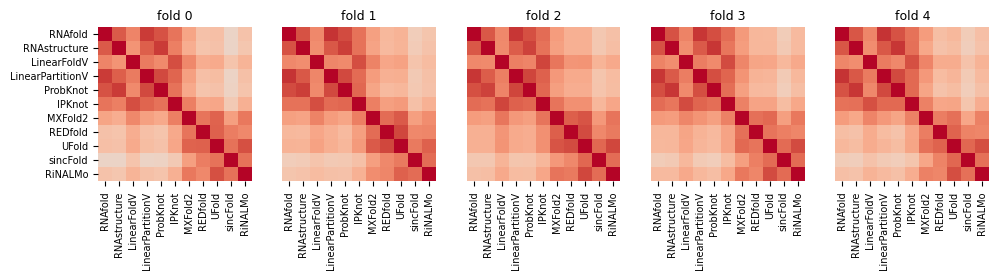

In [5]:
partition_name = "random_kfolds"
summary_kfold = load_summary("archiveII", partition_name)
summary_kfold.replace('MxFold2', 'MXFold2', inplace=True)

corr_list = []
titles = []
for i in range(5):
    corr_list.append(corr_matrix_for(summary_kfold, "fold", i))
    titles.append(f"fold {i}")
plot_corr_strip(corr_list, titles, ncols=5, show_cbar=False, fname=FIG_PATH+"Fig_S5a_kfold.pdf")


## b) Clustering folds

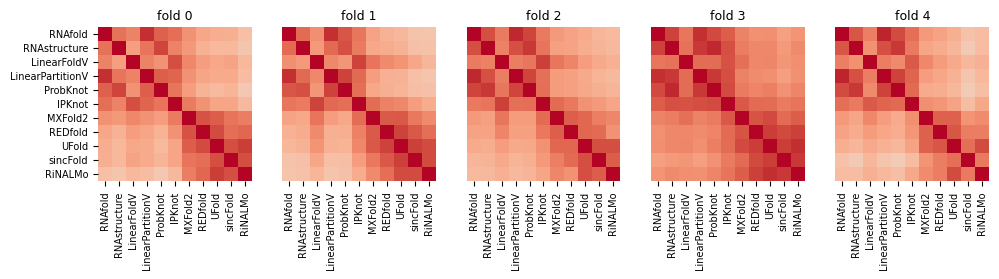

In [6]:
partition_name = "clustering_folds"
summary_cfold = load_summary("archiveII", partition_name)
summary_cfold.replace('MxFold2', 'MXFold2', inplace=True)

corr_list = []
titles = []
for i in range(5):
    corr_list.append(corr_matrix_for(summary_cfold, "fold", i))
    titles.append(f"fold {i}")
plot_corr_strip(corr_list, titles, ncols=5, show_cbar=False, fname=FIG_PATH+"Fig_S5b_cfold.pdf")


## c) Family folds

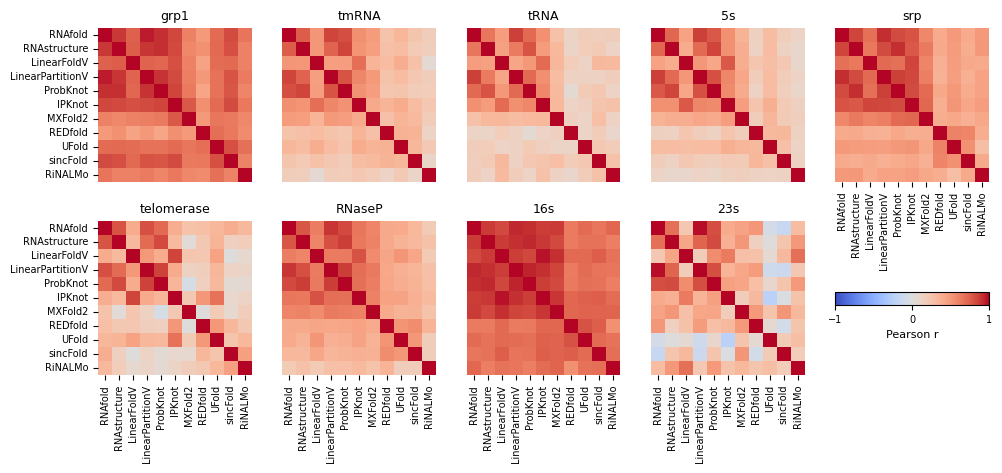

In [7]:
partition_name = "fam_folds"
summary_ffold = load_summary("archiveII", partition_name)
summary_ffold.replace('MxFold2', 'MXFold2', inplace=True)

fam_names = ['grp1', 'tmRNA', 'tRNA', '5s', 'srp', 'telomerase', 'RNaseP', '16s', '23s']

corr_list = []
for i in range(9):
    corr_list.append(corr_matrix_for(summary_ffold, "fold", i))
plot_corr_strip(corr_list, fam_names, ncols=5, show_cbar=True, fname=FIG_PATH+"Fig_S5c_famfold.pdf")


## d) Human Learned folds

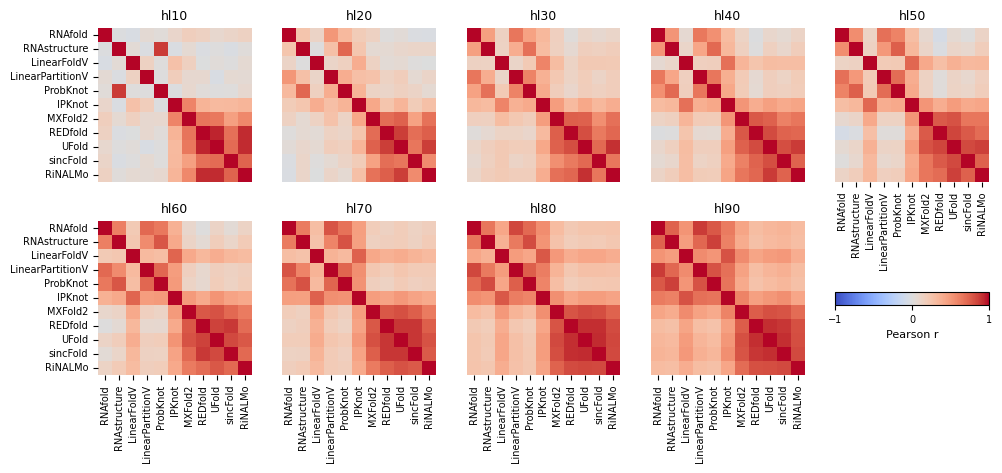

In [8]:
partition_name = "hl_folds"
summary_hlfold = load_summary("archiveII", partition_name)
summary_hlfold.replace('MxFold2', 'MXFold2', inplace=True)

list_hl = ['hl10', 'hl20', 'hl30', 'hl40', 'hl50', 'hl60', 'hl70', 'hl80', 'hl90']

corr_list = []
for hl in list_hl:
    corr_list.append(corr_matrix_for(summary_hlfold, "fold", hl))
plot_corr_strip(corr_list, list_hl, ncols=5, show_cbar=True, fname=FIG_PATH+"Fig_S5d_hlfold.pdf")


## e) Similarity folds

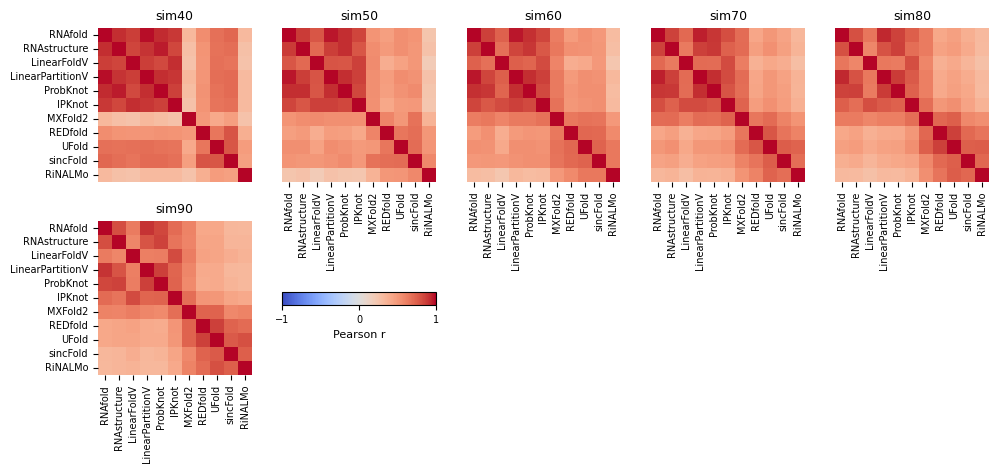

In [9]:
summary_sfold = load_summary("archiveII", "sim_folds")
summary_sfold.replace('MxFold2', 'MXFold2', inplace=True)

list_sim = ['sim40', 'sim50', 'sim60', 'sim70', 'sim80', 'sim90']

corr_list = []
for sim in list_sim:
    corr_list.append(corr_matrix_for(summary_sfold, "similarity", sim))
plot_corr_strip(corr_list, list_sim, ncols=5, show_cbar=True, fname=FIG_PATH+"Fig_S5e_simfold.pdf")
